# Experiment 6: A simple neural network (NumPy only)
2-4-1 sigmoid network trained on XOR by full-batch gradient descent with hand-written backprop.
Convergence criterion used throughout: final MSE < 1e-3 AND every output within 0.1 of its target.

In [1]:
import json, os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

os.makedirs('figs', exist_ok=True)
mpl.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'],
                     'font.size': 10, 'axes.grid': True, 'grid.color': '0.88', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.4,
                     'legend.frameon': False, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
R = {}

In [2]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)          # XOR

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def forward(params, X):
    W1, b1, W2, b2 = params
    h = sigmoid(X @ W1 + b1)                              # hidden activations, 4 x hidden
    return h, sigmoid(h @ W2 + b2)                        # output, 4 x 1

HIDDEN, EPOCHS, SEED = 4, 20000, 1

def init(seed=SEED, hidden=HIDDEN, zero=False):
    rng = np.random.default_rng(seed)
    if zero:
        return [np.zeros((2, hidden)), np.zeros((1, hidden)), np.zeros((hidden, 1)), np.zeros((1, 1))]
    return [rng.normal(0, 1, (2, hidden)), np.zeros((1, hidden)), rng.normal(0, 1, (hidden, 1)), np.zeros((1, 1))]

def train_xor(lr, epochs=EPOCHS, seed=SEED, zero=False):
    W1, b1, W2, b2 = init(seed, zero=zero)
    loss = np.empty(epochs)
    for e in range(epochs):
        h, o = forward((W1, b1, W2, b2), X)
        loss[e] = np.mean((o - y)**2)
        d_o = (o - y) * o * (1 - o)                       # output delta: dE/dz2 (up to the 2/N factor)
        dW2 = h.T @ d_o; db2 = d_o.sum(0, keepdims=True)
        d_h = (d_o @ W2.T) * h * (1 - h)                  # hidden delta, chain rule through W2
        dW1 = X.T @ d_h; db1 = d_h.sum(0, keepdims=True)
        W2 -= lr*dW2; b2 -= lr*db2                        # gradient descent step
        W1 -= lr*dW1; b1 -= lr*db1
    return (W1, b1, W2, b2), loss

def converged(params, loss):
    o = forward(params, X)[1]
    return bool(loss[-1] < 1e-3 and np.all(np.abs(o - y) < 0.1))

h0, o0 = forward(init(), X)
R['initial_loss'] = float(np.mean((o0 - y)**2))
print('initial loss:', round(R['initial_loss'], 4))

initial loss: 0.2749


## Gradient check: backprop against a finite difference (one weight)

In [3]:
p = init(); eps_fd = 1e-6
h, o = forward(p, X); d_o = (o - y)*o*(1 - o); d_h = (d_o @ p[2].T)*h*(1 - h)
analytic = (X.T @ d_h)[0, 0] * 2 / len(X)                  # dE/dW1[0,0] with E = mean squared error
pp = [a.copy() for a in p]; pp[0][0, 0] += eps_fd
pm = [a.copy() for a in p]; pm[0][0, 0] -= eps_fd
numeric = (np.mean((forward(pp, X)[1] - y)**2) - np.mean((forward(pm, X)[1] - y)**2)) / (2*eps_fd)
R['grad_check'] = dict(analytic=float(analytic), numeric=float(numeric))
print(f'analytic {analytic:.8f} vs numeric {numeric:.8f}')

analytic 0.00092084 vs numeric 0.00092084


## Learning rates

lr= 0.05: final MSE 2.31e-03, converged=False, MSE<0.05 at epoch 7721, loss rose in 0 epochs, outputs [0.039 0.953 0.954 0.058]


lr=  0.5: final MSE 1.11e-04, converged=True, MSE<0.05 at epoch 774, loss rose in 0 epochs, outputs [0.008 0.989 0.991 0.013]


lr=  2.0: final MSE 2.46e-05, converged=True, MSE<0.05 at epoch 194, loss rose in 0 epochs, outputs [0.004 0.995 0.996 0.006]


lr= 10.0: final MSE 5.81e-06, converged=True, MSE<0.05 at epoch 63, loss rose in 23 epochs, outputs [0.002 0.998 0.998 0.003]


zero init, lr=2.0: final MSE 0.25 | hidden columns of W1 identical: True
best run: lr = 2.0


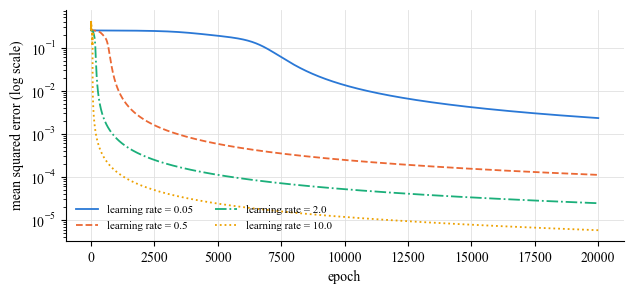

In [4]:
LRS = (0.05, 0.5, 2.0, 10.0)
runs = {}
for lr in LRS:
    params, loss = train_xor(lr)
    o = forward(params, X)[1].ravel()
    below = np.flatnonzero(loss < 0.05)
    runs[lr] = dict(params=params, loss=loss)
    R.setdefault('lr', []).append(dict(lr=lr, final_mse=float(loss[-1]), converged=converged(params, loss),
                                       epoch_mse_below_0_05=int(below[0]) if below.size else None,
                                       epochs_loss_rose=int((np.diff(loss) > 0).sum()),
                                       max_rise=float(np.diff(loss).max()), outputs=o.round(3).tolist()))
    print(f'lr={lr:>5}: final MSE {loss[-1]:.2e}, converged={converged(params, loss)}, '
          f'MSE<0.05 at epoch {below[0] if below.size else "never"}, loss rose in {(np.diff(loss) > 0).sum()} epochs, '
          f'outputs {o.round(3)}')

zp, zl = train_xor(2.0, zero=True)
R['zero_init'] = dict(final_mse=float(zl[-1]), W1=zp[0].round(4).tolist(), outputs=forward(zp, X)[1].ravel().round(3).tolist())
print('zero init, lr=2.0: final MSE', round(zl[-1], 4), '| hidden columns of W1 identical:',
      bool(np.allclose(zp[0], zp[0][:, :1])))

# best run = lowest final MSE among runs that converged AND whose loss never rose (stable descent)
conv = [r for r in R['lr'] if r['converged'] and r['epochs_loss_rose'] == 0]
best = min(conv, key=lambda r: r['final_mse'])
R['best_lr'] = best['lr']
print('best run: lr =', best['lr'])

fig, ax = plt.subplots(figsize=(7.2, 3.0))
for lr, c, ls in zip(LRS, C, ['-', '--', '-.', ':']):
    ax.semilogy(runs[lr]['loss'], color=c, ls=ls, lw=1.3, label=f'learning rate = {lr}')
ax.set_xlabel('epoch'); ax.set_ylabel('mean squared error (log scale)')
ax.legend(loc='lower left', fontsize=8, ncol=2)
fig.savefig('figs/fig6_1_loss.png'); plt.show()

## Decision boundary of the best run

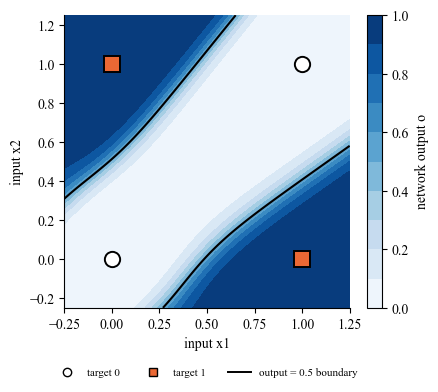

In [5]:
W1, b1, W2, b2 = runs[best['lr']]['params']
gx, gy = np.meshgrid(np.linspace(-0.25, 1.25, 300), np.linspace(-0.25, 1.25, 300))
G = np.c_[gx.ravel(), gy.ravel()]
Z = forward((W1, b1, W2, b2), G)[1].reshape(gx.shape)
fig, ax = plt.subplots(figsize=(4.6, 3.8))
cf = ax.contourf(gx, gy, Z, levels=np.linspace(0, 1, 11), cmap='Blues')
ax.contour(gx, gy, Z, levels=[0.5], colors='k', linewidths=1.5)
for (x1, x2), t in zip(X, y.ravel()):
    ax.plot(x1, x2, 'o' if t == 0 else 's', ms=11, mfc='white' if t == 0 else C[1], mec='k', mew=1.4)
ax.plot([], [], 'o', mfc='white', mec='k', label='target 0'); ax.plot([], [], 's', mfc=C[1], mec='k', label='target 1')
ax.plot([], [], color='k', label='output = 0.5 boundary')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=8)
fig.colorbar(cf, ax=ax, label='network output o')
ax.set_xlabel('input x1'); ax.set_ylabel('input x2'); ax.grid(False)
fig.savefig('figs/fig6_2_boundary.png'); plt.show()

## Where does a large learning rate finally break? (manual: "try 10.0 and record what happens")

In [6]:
for lr in (20.0, 50.0, 100.0, 200.0):
    params, loss = train_xor(lr)
    o = forward(params, X)[1].ravel()
    R.setdefault('lr_probe', []).append(dict(lr=lr, final_mse=float(loss[-1]), converged=converged(params, loss),
                                             max_jump=float(np.max(np.diff(loss))), outputs=o.round(3).tolist()))
    print(f'lr={lr:>6}: final MSE {loss[-1]:.2e}, converged={converged(params, loss)}, '
          f'largest loss increase in one epoch {np.max(np.diff(loss)):.2e}, outputs {o.round(3)}')

lr=  20.0: final MSE 2.96e-06, converged=True, largest loss increase in one epoch 2.21e-01, outputs [0.001 0.998 0.998 0.002]


lr=  50.0: final MSE 5.00e-01, converged=False, largest loss increase in one epoch 2.59e-01, outputs [0. 0. 0. 0.]


lr= 100.0: final MSE 5.00e-01, converged=False, largest loss increase in one epoch 2.25e-01, outputs [0. 0. 0. 0.]


lr= 200.0: final MSE 5.00e-01, converged=False, largest loss increase in one epoch 2.25e-01, outputs [0. 0. 0. 0.]


In [7]:
with open('results.json', 'w') as fh:
    json.dump(R, fh, indent=1)
print('saved results.json')

saved results.json
